In [87]:
# STEP 1: Where the data lives
# All six files are on Zenodo. No login needed.
# DOI: https://doi.org/10.5281/zenodo.21191468

# 2024 files
awards_2024_url    = "https://zenodo.org/records/21191468/files/awards_2024.csv?download=1"
suppliers_2024_url = "https://zenodo.org/records/21191468/files/awards_suppliers_2024.csv?download=1"
main_2024_url      = "https://zenodo.org/records/21191468/files/main_2024.csv?download=1"

# 2025 files
awards_2025_url    = "https://zenodo.org/records/21191468/files/awards_2025.csv?download=1"
suppliers_2025_url = "https://zenodo.org/records/21191468/files/awards_suppliers_2025.csv?download=1"
main_2025_url      = "https://zenodo.org/records/21191468/files/main_2025.csv?download=1"

print("File links are set. Nothing is loaded yet.")

File links are set. Nothing is loaded yet.


In [88]:
import pandas as pd

# STEP 2: Load the six files
# The links come from Step 1.

# 2024 files
awards_2024    = pd.read_csv(awards_2024_url)
suppliers_2024 = pd.read_csv(suppliers_2024_url)
main_2024      = pd.read_csv(main_2024_url)

# 2025 files
awards_2025    = pd.read_csv(awards_2025_url)
suppliers_2025 = pd.read_csv(suppliers_2025_url)
main_2025      = pd.read_csv(main_2025_url)

# Check the sizes (rows, columns)
print("2024 -> awards:", awards_2024.shape, "| suppliers:", suppliers_2024.shape, "| main:", main_2024.shape)
print("2025 -> awards:", awards_2025.shape, "| suppliers:", suppliers_2025.shape, "| main:", main_2025.shape)

2024 -> awards: (29205, 8) | suppliers: (21389, 5) | main: (58971, 15)
2025 -> awards: (11476, 9) | suppliers: (11423, 5) | main: (33259, 14)


In [89]:
# STEP 3: Stack 2024 and 2025 into one table per file type

awards    = pd.concat([awards_2024, awards_2025], ignore_index=True)
suppliers = pd.concat([suppliers_2024, suppliers_2025], ignore_index=True)
main      = pd.concat([main_2024, main_2025], ignore_index=True)

print("Awards:", awards.shape)
print("Suppliers:", suppliers.shape)
print("Main:", main.shape)

Awards: (40681, 9)
Suppliers: (32812, 5)
Main: (92230, 15)


In [90]:
# STEP 4: Add the buyer name and procurement method to each award

# The buyer details sit in the main file.
# I match them to awards using main_ocid and main_id.
main_small = main[["ocid", "id", "buyer_name", "tender_procurementMethod"]].copy()
main_small = main_small.rename(columns={"ocid": "main_ocid", "id": "main_id"})

# how="left" keeps every award, even if no buyer is found
awards_with_buyer = awards.merge(
    main_small,
    on=["main_ocid", "main_id"],
    how="left"
)

print("Awards with buyer info:", awards_with_buyer.shape)

Awards with buyer info: (40681, 11)


In [91]:
# STEP 5: Add the supplier name to each award

# The supplier file links a supplier name to an award id.
suppliers_small = suppliers[["awards_id", "name"]].copy()
suppliers_small = suppliers_small.rename(columns={"awards_id": "id", "name": "vendor"})

# how="left" keeps every award. Awards with no supplier get a blank vendor.
audit_df = awards_with_buyer.merge(
    suppliers_small,
    on="id",
    how="left"
)

print("Final merged table:", audit_df.shape)
audit_df.head()

Final merged table: (40681, 12)


,id,title,value_amount,value_currency,main_ocid,main_id,contractPeriod_startDate,contractPeriod_endDate,description,buyer_name,tender_procurementMethod,vendor
0,20250205150259-34156,SUPPLY AND DELIVERY OF SEWING MACHINES,125000.0,KES,ocds-5whusi-001,ocds-5whusi-001-2024-04-11T15:23:50+03:00,NaN,NaN,NaN,Masai Technical Training Institute,open,MUTINDWA UNIFORMS AND TEXTILES
1,20240304115311-74742,Provision of return Air Tickets for PCS and de...,360550.0,KES,ocds-5whusi-002/11/2023,ocds-5whusi-002/11/2023-2024-03-04T11:45:44+03:00,2023-11-01T00:00:00+03:00,NaN,NaN,Office of the Prime Cabinet Secretary,open,THORAYA AGENCIES LIMITED
2,20240521115322-83963,Provision of Return Air tickets to Eldoret to ...,39320.0,KES,ocds-5whusi-003/02/2024,ocds-5whusi-003/02/2024-2024-05-21T11:43:35+03:00,2024-02-22T00:00:00+03:00,2024-03-22T00:00:00+03:00,NaN,Office of the Prime Cabinet Secretary,open,ATTIC TOURS AND TRAVEL
3,20240305103958-74843,Provision of Return Air Ticket to COS while on...,55950.0,KES,ocds-5whusi-004/08/2023,ocds-5whusi-004/08/2023-2024-03-05T10:33:59+03:00,2023-08-15T00:00:00+03:00,NaN,NaN,Office of the Prime Cabinet Secretary,open,SILVER AFRICA TOURS & SAFARIS LIMITED
4,20240305111012-74857,Provision of Return Air Ticket for COS-Busines...,1599900.0,KES,ocds-5whusi-005/11/2023,ocds-5whusi-005/11/2023-2024-03-05T11:05:13+03:00,2023-11-15T00:00:00+03:00,NaN,NaN,Office of the Prime Cabinet Secretary,open,THORAYA AGENCIES LIMITED


In [92]:
# STEP 6: Check that the supplier merge did not add extra rows

# If an award had two suppliers, Step 5 would give it two rows.
# So I count award ids that appear more than once.
duplicate_count = audit_df["id"].duplicated().sum()

print("Duplicate award ids after the merge:", duplicate_count)

if duplicate_count > 0:
    print("\nSome awards list more than one supplier. Here is a sample:")
    dup_ids = audit_df[audit_df["id"].duplicated(keep=False)]["id"].unique()[:5]
    print(audit_df[audit_df["id"].isin(dup_ids)][["id", "vendor", "value_amount"]].sort_values("id"))
else:
    print("No duplicates. Each award has exactly one row.")

Duplicate award ids after the merge: 0
No duplicates. Each award has exactly one row.


In [93]:
# STEP 7: Turn the date columns into real dates

# Libraries used in the later steps
from scipy import stats
from sklearn.ensemble import IsolationForest

# 1. Contract period dates. Anything unreadable becomes blank.
audit_df["contractPeriod_startDate"] = pd.to_datetime(audit_df["contractPeriod_startDate"], utc=True, errors="coerce")
audit_df["contractPeriod_endDate"]   = pd.to_datetime(audit_df["contractPeriod_endDate"], utc=True, errors="coerce")

# 2. Record date and month, taken from the first 14 digits of each award id
audit_df["id_timestamp"]  = pd.to_datetime(audit_df["id"].str[:14], format="%Y%m%d%H%M%S", errors="coerce")
audit_df["id_year_month"] = audit_df["id_timestamp"].dt.to_period("M")

In [94]:
# STEP 8: Rule-based flags

# Start with every contract marked normal
audit_df["flag"] = "normal"

# Rule 1: no supplier name recorded
audit_df.loc[audit_df["vendor"].isnull(), "flag"] = "missing_supplier"

# Rule 2: contract value is zero
audit_df.loc[audit_df["value_amount"] == 0, "flag"] = "zero_value_contract"

# Rule 3: awarded by direct procurement, so no competitive bidding
audit_df.loc[audit_df["tender_procurementMethod"] == "direct", "flag"] = "direct_procurement"

# Fill blanks so later steps do not break
audit_df["vendor"]                   = audit_df["vendor"].fillna("UNKNOWN")
audit_df["buyer_name"]               = audit_df["buyer_name"].fillna("UNKNOWN")
audit_df["tender_procurementMethod"] = audit_df["tender_procurementMethod"].fillna("UNKNOWN")

print("Flag counts from the rules:")
print(audit_df["flag"].value_counts())

Flag counts from the rules:
flag
normal                 31783
missing_supplier        7709
direct_procurement       876
zero_value_contract      313
Name: count, dtype: int64


In [95]:
# STEP 9: Z-score check on contract value

# A Z-score says how many standard deviations a value sits from the average.
# Blank values count as 0. Step 25 showed that none are blank.
valid_amount = audit_df["value_amount"].fillna(0)
audit_df["amount_zscore"] = stats.zscore(valid_amount)

# Flag any contract more than 3 standard deviations from the average, high or low
audit_df["zscore_flag"] = audit_df["amount_zscore"].abs() > 3

print("Z-score flagged contracts:", audit_df["zscore_flag"].sum())

Z-score flagged contracts: 38


In [96]:
# STEP 10: Isolation Forest
# It scores how unusual each contract is compared with the others.

from sklearn.preprocessing import LabelEncoder

# 1. The model needs numbers, so I turn each text column into number codes
le_dept     = LabelEncoder()
le_vendor   = LabelEncoder()
le_approver = LabelEncoder()

audit_df["dept_encoded"]     = le_dept.fit_transform(audit_df["buyer_name"])
audit_df["vendor_encoded"]   = le_vendor.fit_transform(audit_df["vendor"])
audit_df["approver_encoded"] = le_approver.fit_transform(audit_df["tender_procurementMethod"])   # this holds the procurement method

# 2. The four inputs: contract value, buyer, supplier, procurement method
features = audit_df[["value_amount", "dept_encoded", "vendor_encoded", "approver_encoded"]].fillna(0)

# 3. Fit once on all contracts. 5% contamination, as in the paper. The seed keeps results the same on every run.
model = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
audit_df["iso_flag"] = model.fit_predict(features)
audit_df["iso_flag"] = audit_df["iso_flag"].map({1: "normal", -1: "anomaly"})

print("Isolation Forest results:")
print(audit_df["iso_flag"].value_counts())

Isolation Forest results:
iso_flag
normal     38655
anomaly     2026
Name: count, dtype: int64


In [97]:
# STEP 11: One combined "is flagged" column

# A contract is flagged if any method marked it:
# a rule from Step 8, the Z-score, or the Isolation Forest
audit_df["is_flagged"] = (
    (audit_df["flag"] != "normal") |
    (audit_df["zscore_flag"] == True) |
    (audit_df["iso_flag"] == "anomaly")
)

print("Flagged contracts:", audit_df["is_flagged"].sum())
print("All contracts:", len(audit_df))

Flagged contracts: 10253
All contracts: 40681


In [98]:
# STEP 12: Monthly flag rate (the outcome variable)

# I date each contract by the timestamp inside its id, not the contract period.
# This cut the rows outside the window from 18.06% to 2.55%.
# This is a first pass over 2024 and 2025. Step 14 trims it to the final window.

# 1. First pass window: January 2024 to December 2025
study_start = pd.Period("2024-01", freq="M")
study_end   = pd.Period("2025-12", freq="M")

outside_window = (audit_df["id_year_month"] < study_start) | (audit_df["id_year_month"] > study_end)

print("Contracts outside the window:", outside_window.sum())
print("Share of all contracts:", round(outside_window.sum() / len(audit_df) * 100, 2), "%")

# 2. Label these rows instead of deleting them quietly
audit_df.loc[outside_window, "flag"] = "date_outside_study_window"

# 3. Keep only the rows inside the window
in_window = audit_df[~outside_window].copy()

# 4. Count contracts and flagged contracts in each month
monthly_total   = in_window.groupby("id_year_month")["id"].count()
monthly_flagged = in_window[in_window["is_flagged"] == True].groupby("id_year_month")["id"].count()

monthly_summary = pd.DataFrame({
    "total_contracts":   monthly_total,
    "flagged_contracts": monthly_flagged
})

# 5. Months with no flagged contracts show a blank, so I set them to 0, then work out the rate
monthly_summary["flagged_contracts"] = monthly_summary["flagged_contracts"].fillna(0)
monthly_summary["flag_rate"] = monthly_summary["flagged_contracts"] / monthly_summary["total_contracts"]

print("\nMonthly flag rate, first pass:")
print(monthly_summary)

monthly_summary.to_csv("monthly_flag_rate_2024_2025.csv")
print("\nSaved: monthly_flag_rate_2024_2025.csv")

Contracts outside the window: 1038
Share of all contracts: 2.55 %

Monthly flag rate, first pass:
               total_contracts  flagged_contracts  flag_rate
id_year_month                                               
2024-01                   1375                629   0.457455
2024-02                   1446                654   0.452282
2024-03                   1999                853   0.426713
2024-04                   1831                858   0.468596
2024-05                   2114                979   0.463103
2024-06                   2608               1129   0.432899
2024-07                   5359               2619   0.488711
2024-08                   1516                447   0.294855
2024-09                   2211                266   0.120308
2024-10                   1896                226   0.119198
2024-11                   1706                186   0.109027
2024-12                   1837                211   0.114861
2025-01                   2626                23

In [99]:
# STEP 13: Is the late-2025 data really thin?

# I look at the raw ids from July 2025 onward, before any date handling.
# This shows whether the id format changed, or whether there is simply little data.
# Note: this count includes rows stamped 2026 too. Step 24 splits it by year.
check_ids = audit_df[audit_df["id_year_month"] >= pd.Period("2025-07", freq="M")]

print("Rows stamped July 2025 or later (2025 and 2026 together):", len(check_ids))
print("\nSample of their raw ids:")
print(check_ids["id"].head(15).tolist())

# Also check for ids whose date could not be read at all
unparseable = audit_df["id_timestamp"].isnull().sum()
print("\nRows where the id date failed to parse:", unparseable)
print("Share of all contracts:", round(unparseable / len(audit_df) * 100, 2), "%")

Rows stamped July 2025 or later (2025 and 2026 together): 927

Sample of their raw ids:
['20250715144022-132978', '20250730101924-135907', '20251008173313-144542', '20250916141301-140855', '20250818122643-138289', '20250903134532-139795', '20251023171441-147452', '20250911105315-140424', '20250911105810-140427', '20250911110303-140430', '20251006132613-143754', '20251008151433-144446', '20251008112854-144313', '20251008113226-144318', '20251008114243-144322']

Rows where the id date failed to parse: 0
Share of all contracts: 0.0 %


In [100]:
# STEP 14A: Cut the data to the final study window

# Late 2025 is thin. July to December 2025 has only 294 contracts across six months,
# against 1,375 to 5,359 a month before. (Another 633 rows are stamped 2026.)
# So the final window is January 2024 to June 2025.
study_start = pd.Period("2024-01", freq="M")
study_end   = pd.Period("2025-06", freq="M")

outside_window = (audit_df["id_year_month"] < study_start) | (audit_df["id_year_month"] > study_end)

print("Contracts outside the final window:", outside_window.sum())
print("Share of all contracts:", round(outside_window.sum() / len(audit_df) * 100, 2), "%")

# Label these rows instead of deleting them quietly
audit_df.loc[outside_window, "flag"] = "date_outside_study_window"

# Keep only the rows inside the final window
in_window = audit_df[~outside_window].copy()

# Count contracts and flagged contracts in each month
monthly_total   = in_window.groupby("id_year_month")["id"].count()
monthly_flagged = in_window[in_window["is_flagged"] == True].groupby("id_year_month")["id"].count()

monthly_summary = pd.DataFrame({
    "total_contracts":   monthly_total,
    "flagged_contracts": monthly_flagged
})

# Months with no flagged contracts show a blank, so I set them to 0, then work out the rate
monthly_summary["flagged_contracts"] = monthly_summary["flagged_contracts"].fillna(0)
monthly_summary["flag_rate"] = monthly_summary["flagged_contracts"] / monthly_summary["total_contracts"]

print("\nFinal monthly flag rate, January 2024 to June 2025:")
print(monthly_summary)

monthly_summary.to_csv("monthly_flag_rate_final.csv")
print("\nSaved: monthly_flag_rate_final.csv")

Contracts outside the final window: 1332
Share of all contracts: 3.27 %

Final monthly flag rate, January 2024 to June 2025:
               total_contracts  flagged_contracts  flag_rate
id_year_month                                               
2024-01                   1375                629   0.457455
2024-02                   1446                654   0.452282
2024-03                   1999                853   0.426713
2024-04                   1831                858   0.468596
2024-05                   2114                979   0.463103
2024-06                   2608               1129   0.432899
2024-07                   5359               2619   0.488711
2024-08                   1516                447   0.294855
2024-09                   2211                266   0.120308
2024-10                   1896                226   0.119198
2024-11                   1706                186   0.109027
2024-12                   1837                211   0.114861
2025-01              

In [101]:
# STEP 14B: Which flag drives the drop?

# 1. One true/false column for each kind of flag
audit_df["no_supplier"] = audit_df["vendor"] == "UNKNOWN"
audit_df["zero_value"]  = audit_df["value_amount"] == 0
audit_df["direct"]      = audit_df["tender_procurementMethod"] == "direct"
audit_df["zscore"]      = audit_df["zscore_flag"]
audit_df["isolation"]   = audit_df["iso_flag"] == "anomaly"

# 2. Flagged by anything except the missing-supplier rule
audit_df["flagged_other"] = audit_df[["zero_value", "direct", "zscore", "isolation"]].any(axis=1)

# 3. Share of each month's contracts caught by each flag
in_window = audit_df[~outside_window]
flag_columns = ["no_supplier", "zero_value", "direct", "zscore", "isolation", "flagged_other", "is_flagged"]

monthly = in_window.groupby("id_year_month")[flag_columns].mean().round(3)
print(monthly)

# Total contracts caught by each flag
print(in_window[flag_columns].sum())
monthly.to_csv("flag_rates_by_type.csv")


# STEP 14C: Rerun the two-reform model on two outcomes
import statsmodels.api as sm

# 1. One row per month, with a 0/1 marker for each reform and a month counter
months = monthly.reset_index()
months["after_digitization"] = (months["id_year_month"] >= pd.Period("2024-08", freq="M")).astype(int)
months["after_levy"]         = (months["id_year_month"] >= pd.Period("2024-09", freq="M")).astype(int)
months["month_number"]       = range(len(months))
X = sm.add_constant(months[["after_digitization", "after_levy", "month_number"]])

# 2. Model A: every flag except missing supplier
print(sm.OLS(months["flagged_other"], X).fit().summary())

# 3. Model B: missing supplier on its own
print(sm.OLS(months["no_supplier"], X).fit().summary())

               no_supplier  zero_value  direct  zscore  isolation  \
id_year_month                                                       
2024-01              0.438       0.001   0.025   0.000      0.028   
2024-02              0.406       0.000   0.041   0.000      0.048   
2024-03              0.399       0.007   0.022   0.001      0.036   
2024-04              0.451       0.000   0.010   0.000      0.021   
2024-05              0.449       0.009   0.014   0.000      0.024   
2024-06              0.419       0.006   0.005   0.000      0.020   
2024-07              0.469       0.003   0.014   0.000      0.028   
2024-08              0.199       0.025   0.043   0.005      0.069   
2024-09              0.009       0.016   0.025   0.000      0.089   
2024-10              0.010       0.017   0.028   0.001      0.084   
2024-11              0.006       0.004   0.026   0.002      0.090   
2024-12              0.005       0.006   0.035   0.000      0.097   
2025-01              0.006       0

In [102]:
# STEP 15: Single-intervention model
# Question: is the monthly flag rate different after the reforms,
# once I allow for a steady trend over time?

import statsmodels.api as sm

# 1. Start from the monthly table, one row per month
model_data = monthly_summary.copy()
model_data = model_data.reset_index()

# 2. Mark each month 0 or 1. 1 means September 2024 or later.
#    August 2024 stays at 0 here, so the first 8 months count as untreated.
reform_date = pd.Period("2024-09", freq="M")
model_data["after_reform"] = (model_data["id_year_month"] >= reform_date).astype(int)

# 3. A month counter, so the model can pick up a steady trend
model_data["month_number"] = range(len(model_data))

# 4. Outcome: the monthly flag rate. Predictors: the reform marker and the trend.
X = model_data[["after_reform", "month_number"]]
X = sm.add_constant(X)   # adds the starting level (intercept)
y = model_data["flag_rate"]

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              flag_rate   R-squared:                       0.961
Model:                            OLS   Adj. R-squared:                  0.956
Method:                 Least Squares   F-statistic:                     186.7
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           2.52e-11
Time:                        11:39:54   Log-Likelihood:                 34.972
No. Observations:                  18   AIC:                            -63.94
Df Residuals:                      15   BIC:                            -61.27
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.4654      0.018     25.927   

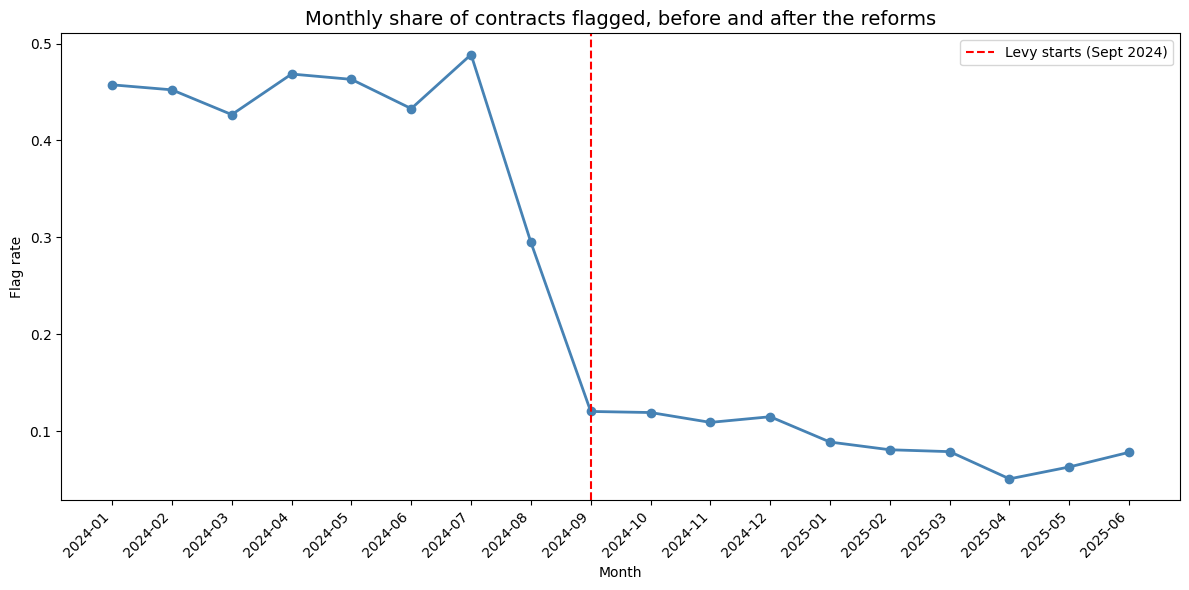

Chart saved as flag_rate_over_time.png


In [103]:
# STEP 16: Plot the flag rate over time
# I want to see the break by eye, and check it is not just noise.

import matplotlib.pyplot as plt

# 1. Turn each month into plain text so it plots cleanly
plot_data = model_data.copy()
plot_data["month_label"] = plot_data["id_year_month"].astype(str)

plt.figure(figsize=(12, 6))

# 2. Draw the flag rate, month by month
plt.plot(
    plot_data["month_label"],
    plot_data["flag_rate"],
    marker="o",
    color="steelblue",
    linewidth=2
)

# 3. Draw a dashed line at September 2024, when the levy took effect
reform_index = plot_data[plot_data["id_year_month"] == pd.Period("2024-09", freq="M")].index[0]
plt.axvline(x=reform_index, color="red", linestyle="--", label="Levy starts (Sept 2024)")

# 4. Titles and labels
plt.title("Monthly share of contracts flagged, before and after the reforms", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Flag rate")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig("flag_rate_over_time.png", dpi=150)
plt.show()

print("Chart saved as flag_rate_over_time.png")

In [104]:
# STEP 17: Decomposed model
# I split the two reforms: the portal upgrade (August 2024)
# and the levy (September 2024).

import statsmodels.api as sm

# 1. Start from the monthly table
model_data2 = monthly_summary.copy()
model_data2 = model_data2.reset_index()

# 2. Marker 1: turns on from August 2024, when the portal was upgraded
digitization_start = pd.Period("2024-08", freq="M")
model_data2["after_digitization"] = (model_data2["id_year_month"] >= digitization_start).astype(int)

# 3. Marker 2: turns on from September 2024, when the levy began
levy_start = pd.Period("2024-09", freq="M")
model_data2["after_levy"] = (model_data2["id_year_month"] >= levy_start).astype(int)

# 4. The same month counter for the trend
model_data2["month_number"] = range(len(model_data2))

# 5. Outcome: the monthly flag rate
X = model_data2[["after_digitization", "after_levy", "month_number"]]
X = sm.add_constant(X)
y = model_data2["flag_rate"]

model2 = sm.OLS(y, X).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:              flag_rate   R-squared:                       0.990
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     445.6
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           4.02e-14
Time:                        11:39:55   Log-Likelihood:                 46.811
No. Observations:                  18   AIC:                            -85.62
Df Residuals:                      14   BIC:                            -82.06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.4692      0

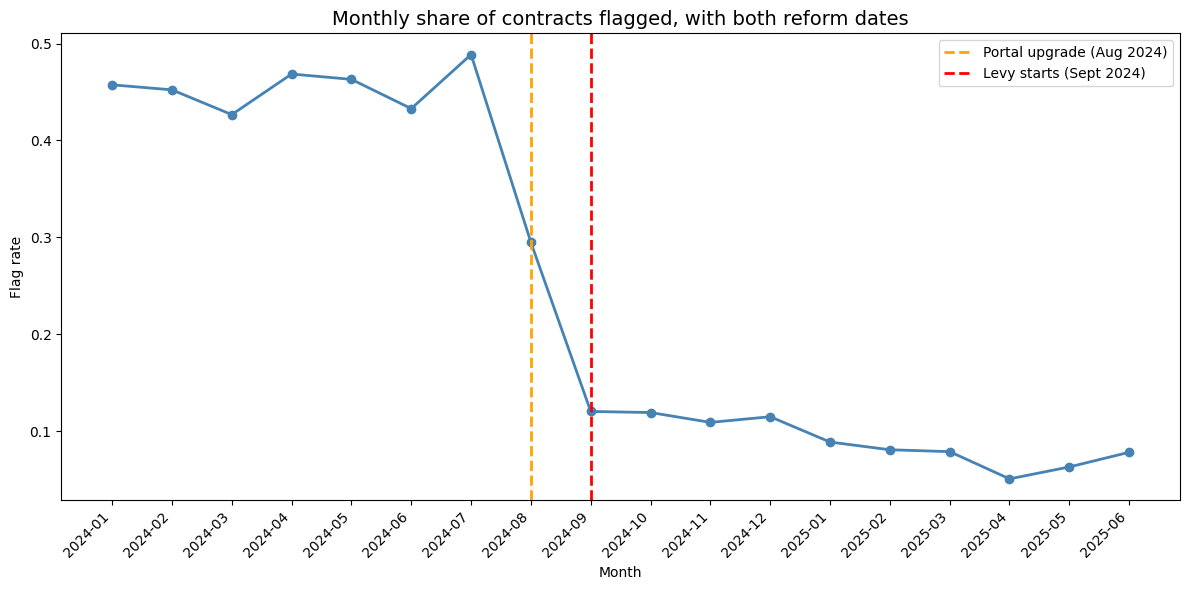

Chart saved as flag_rate_two_effects.png


In [105]:
# STEP 18: Plot the flag rate with both reform dates marked
# Orange line: portal upgrade (August 2024)
# Red line: levy (September 2024)

import matplotlib.pyplot as plt

# 1. Turn each month into plain text so it plots cleanly
plot_data = model_data2.copy()
plot_data["month_label"] = plot_data["id_year_month"].astype(str)

plt.figure(figsize=(12, 6))

# 2. Draw the flag rate, one dot per month
plt.plot(
    plot_data["month_label"],
    plot_data["flag_rate"],
    marker="o",
    color="steelblue",
    linewidth=2
)

# 3. Find where August and September 2024 sit in the table
digitization_index = plot_data[
    plot_data["id_year_month"] == pd.Period("2024-08", freq="M")
].index[0]

levy_index = plot_data[
    plot_data["id_year_month"] == pd.Period("2024-09", freq="M")
].index[0]

# 4. Draw the two dashed lines
plt.axvline(
    x=digitization_index,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Portal upgrade (Aug 2024)"
)

plt.axvline(
    x=levy_index,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Levy starts (Sept 2024)"
)

# 5. Titles and labels, then save
plt.title("Monthly share of contracts flagged, with both reform dates", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Flag rate")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig("flag_rate_two_effects.png", dpi=150)
plt.show()

print("Chart saved as flag_rate_two_effects.png")

In [106]:
# STEP 19: What is in the main file?
# I check the columns and the "tag" column, to see whether
# the file records a status for each award.

print(main.columns.tolist())
print()
print(main["tag"].value_counts(dropna=False))

['id', 'tag', 'date', 'ocid', 'language', 'initiationType', 'buyer_id', 'buyer_name', 'tender_id', 'tender_title', 'tender_mainProcurementCategory', 'tender_procurementMethod', 'tender_tenderPeriod_endDate', 'tender_tenderPeriod_startDate', 'tender_awardCriteria']

tag
compiled    92230
Name: count, dtype: int64


In [107]:
# STEP 20: What do the no-supplier awards look like?
# I compare awards with no supplier against awards that have one.
# If they look alike, a blank supplier is more likely a record gap than misconduct.

# 1. Columns in the awards file. I am looking for any status or date field.
print(awards.columns.tolist())
print()

# 2. Split the awards into two groups
no_supplier  = audit_df[audit_df["vendor"] == "UNKNOWN"]
has_supplier = audit_df[audit_df["vendor"] != "UNKNOWN"]

# 3. Compare the groups (no supplier vs has supplier)
print("Number of awards:", len(no_supplier), "vs", len(has_supplier))
print()
print("Share with a contract value above zero:")
print(round((no_supplier["value_amount"] > 0).mean(), 3), "vs", round((has_supplier["value_amount"] > 0).mean(), 3))
print()
print("Median contract value:")
print(no_supplier["value_amount"].median(), "vs", has_supplier["value_amount"].median())
print()
print("Procurement method, share of each group:")
print("No supplier:")
print(no_supplier["tender_procurementMethod"].value_counts(normalize=True).round(3))
print("Has supplier:")
print(has_supplier["tender_procurementMethod"].value_counts(normalize=True).round(3))

['id', 'title', 'value_amount', 'value_currency', 'main_ocid', 'main_id', 'contractPeriod_startDate', 'contractPeriod_endDate', 'description']

Number of awards: 7869 vs 32812

Share with a contract value above zero:
0.994 vs 0.991

Median contract value:
500000.0 vs 422890.7

Procurement method, share of each group:
No supplier:
tender_procurementMethod
open                    0.967
selective               0.019
direct                  0.015
AlternativeSelection    0.000
Name: proportion, dtype: float64
Has supplier:
tender_procurementMethod
open                    0.938
selective               0.039
direct                  0.023
AlternativeSelection    0.000
Name: proportion, dtype: float64


In [108]:
# STEP 21: Isolation Forest without the supplier
# The supplier column is mostly blank before September 2024, and that alone
# could push the Isolation Forest to flag more contracts afterwards.
# So I refit it without the supplier as an input.

# 1. Same inputs as Step 10, minus the supplier
features_no_vendor = audit_df[["value_amount", "dept_encoded", "approver_encoded"]].fillna(0)

# 2. Same settings as before
model_no_vendor = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
audit_df["iso_no_vendor"] = model_no_vendor.fit_predict(features_no_vendor) == -1

# 3. Flagged by anything except missing supplier, using this new forest
audit_df["flagged_other_v2"] = audit_df[["zero_value", "direct", "zscore", "iso_no_vendor"]].any(axis=1)

# 4. Monthly share, inside the study window only
in_window = audit_df[~outside_window]
monthly_v2 = in_window.groupby("id_year_month")[["iso_no_vendor", "flagged_other_v2"]].mean().round(3)
print(monthly_v2)

# 5. The same two-reform model as Step 14B, on this new outcome
months = monthly_v2.reset_index()
months["after_digitization"] = (months["id_year_month"] >= pd.Period("2024-08", freq="M")).astype(int)
months["after_levy"]         = (months["id_year_month"] >= pd.Period("2024-09", freq="M")).astype(int)
months["month_number"]       = range(len(months))

X = sm.add_constant(months[["after_digitization", "after_levy", "month_number"]])
print(sm.OLS(months["flagged_other_v2"], X).fit().summary())

               iso_no_vendor  flagged_other_v2
id_year_month                                 
2024-01                0.033             0.035
2024-02                0.070             0.071
2024-03                0.039             0.045
2024-04                0.026             0.027
2024-05                0.033             0.041
2024-06                0.020             0.027
2024-07                0.036             0.038
2024-08                0.084             0.101
2024-09                0.057             0.073
2024-10                0.079             0.097
2024-11                0.067             0.071
2024-12                0.082             0.084
2025-01                0.058             0.080
2025-02                0.066             0.074
2025-03                0.047             0.054
2025-04                0.030             0.041
2025-05                0.036             0.047
2025-06                0.059             0.065
                            OLS Regression Results          

In [109]:
# STEP 22: Does the August jump hold at other contamination rates, and without July?
# This is the robustness check on "other flags".

# 1. A helper that runs the two-reform model on one outcome
def run_model(monthly_table, outcome, drop_july=False):
    months = monthly_table.reset_index()
    months["after_digitization"] = (months["id_year_month"] >= pd.Period("2024-08", freq="M")).astype(int)
    months["after_levy"]         = (months["id_year_month"] >= pd.Period("2024-09", freq="M")).astype(int)
    months["month_number"]       = range(len(months))
    if drop_july:
        months = months[months["id_year_month"] != pd.Period("2024-07", freq="M")]
    X = sm.add_constant(months[["after_digitization", "after_levy", "month_number"]])
    return sm.OLS(months[outcome], X).fit()

# 2. Try three contamination rates, without the supplier input
for rate in [0.01, 0.05, 0.10]:
    iso_model = IsolationForest(n_estimators=100, contamination=rate, random_state=42)
    audit_df["iso_test"] = iso_model.fit_predict(features_no_vendor) == -1
    audit_df["other_test"] = audit_df[["zero_value", "direct", "zscore", "iso_test"]].any(axis=1)

    in_window = audit_df[~outside_window]
    monthly_test = in_window.groupby("id_year_month")[["other_test"]].mean()

    result = run_model(monthly_test, "other_test")
    print("Contamination", rate)
    print("  digitization:", round(result.params["after_digitization"], 4), " p =", round(result.pvalues["after_digitization"], 3))
    print("  levy:        ", round(result.params["after_levy"], 4), " p =", round(result.pvalues["after_levy"], 3))
    print()

# 3. The 5% model again, with July 2024 dropped
audit_df["iso_test"] = IsolationForest(n_estimators=100, contamination=0.05, random_state=42).fit_predict(features_no_vendor) == -1
audit_df["other_test"] = audit_df[["zero_value", "direct", "zscore", "iso_test"]].any(axis=1)
in_window = audit_df[~outside_window]
monthly_test = in_window.groupby("id_year_month")[["other_test"]].mean()

result = run_model(monthly_test, "other_test", drop_july=True)
print("5% contamination, July 2024 dropped")
print("  digitization:", round(result.params["after_digitization"], 4), " p =", round(result.pvalues["after_digitization"], 3))
print("  levy:        ", round(result.params["after_levy"], 4), " p =", round(result.pvalues["after_levy"], 3))

Contamination 0.01
  digitization: 0.0616  p = 0.0
  levy:         -0.019  p = 0.063

Contamination 0.05
  digitization: 0.0756  p = 0.0
  levy:         -0.0118  p = 0.463

Contamination 0.1
  digitization: 0.1051  p = 0.0
  levy:         0.0284  p = 0.241

5% contamination, July 2024 dropped
  digitization: 0.0784  p = 0.0
  levy:         -0.0101  p = 0.54


In [110]:
# STEP 23: Which flag drives the August jump?
# I run the two-reform model on each "other" flag on its own.

# 1. Monthly rate for each flag.
#    The Isolation Forest here is the version without the supplier.
flag_rates = monthly[["zero_value", "direct", "zscore"]].copy()
flag_rates["iso_no_vendor"] = monthly_v2["iso_no_vendor"]

# 2. Run the model on each flag, one at a time
for flag_name in flag_rates.columns:
    result = run_model(flag_rates, flag_name)
    print(flag_name)
    print("  digitization:", round(result.params["after_digitization"], 4), " p =", round(result.pvalues["after_digitization"], 3))
    print("  levy:        ", round(result.params["after_levy"], 4), " p =", round(result.pvalues["after_levy"], 3))
    print()

zero_value
  digitization: 0.0227  p = 0.002
  levy:         -0.0126  p = 0.06

direct
  digitization: 0.0312  p = 0.013
  levy:         -0.008  p = 0.491

zscore
  digitization: 0.0047  p = 0.0
  levy:         -0.0043  p = 0.001

iso_no_vendor
  digitization: 0.061  p = 0.002
  levy:         -0.007  p = 0.678



In [111]:
# STEP 24: Which years are the rows from July 2025 onward stamped with?
# Step 13 counted 927 rows from July 2025 on, but that mixes 2025 and 2026.

late_rows = audit_df[audit_df["id_year_month"] >= pd.Period("2025-07", freq="M")]
print(late_rows["id_year_month"].dt.year.value_counts())

id_year_month
2026    633
2025    294
Name: count, dtype: int64


In [112]:
# STEP 25: How many contract values are missing or zero?
# This backs the paper's line that no contract values were missing.

print("Missing contract values:", audit_df["value_amount"].isnull().sum())
print("Contract values equal to zero:", (audit_df["value_amount"] == 0).sum())

Missing contract values: 0
Contract values equal to zero: 350


In [113]:
# STEP 26: What is behind the July 2024 spike?
# July 2024 has 5,359 contracts, against 1,375 to 3,078 in other months.

july_month = pd.Period("2024-07", freq="M")

# 1. Split the study window into July and all other months
in_window = audit_df[~outside_window]
july  = in_window[in_window["id_year_month"] == july_month]
other = in_window[in_window["id_year_month"] != july_month]

# 2. How many awards were stamped on each day in July?
print("Awards per day in July:")
print(july["id_timestamp"].dt.date.value_counts().sort_index())

# 3. Which buyers account for the most awards?
print()
print("Top 5 buyers in July (share of July awards):")
print(july["buyer_name"].value_counts(normalize=True).head(5).round(3))
print()
print("Top 5 buyers in other months (share of those awards):")
print(other["buyer_name"].value_counts(normalize=True).head(5).round(3))

Awards per day in July:
id_timestamp
2024-07-01    105
2024-07-02    149
2024-07-03    262
2024-07-04    192
2024-07-05    214
2024-07-06     27
2024-07-07     31
2024-07-08    189
2024-07-09    248
2024-07-10    284
2024-07-11    332
2024-07-12    282
2024-07-13    117
2024-07-14     62
2024-07-15    348
2024-07-16    242
2024-07-17    239
2024-07-18    223
2024-07-19    223
2024-07-20      7
2024-07-21     10
2024-07-22    209
2024-07-23    151
2024-07-24    203
2024-07-25    180
2024-07-26    156
2024-07-27     12
2024-07-28     10
2024-07-29    200
2024-07-30    256
2024-07-31    196
Name: count, dtype: int64

Top 5 buyers in July (share of July awards):
buyer_name
Makueni County Government            0.109
Elgeyo-Marakwet County Government    0.073
The Meru National Polytechnic        0.057
KENYA MEDICAL RESEARCH INSTITUTE     0.039
Nyandarua County Government          0.038
Name: proportion, dtype: float64

Top 5 buyers in other months (share of those awards):
buyer_name
Kenya Ru

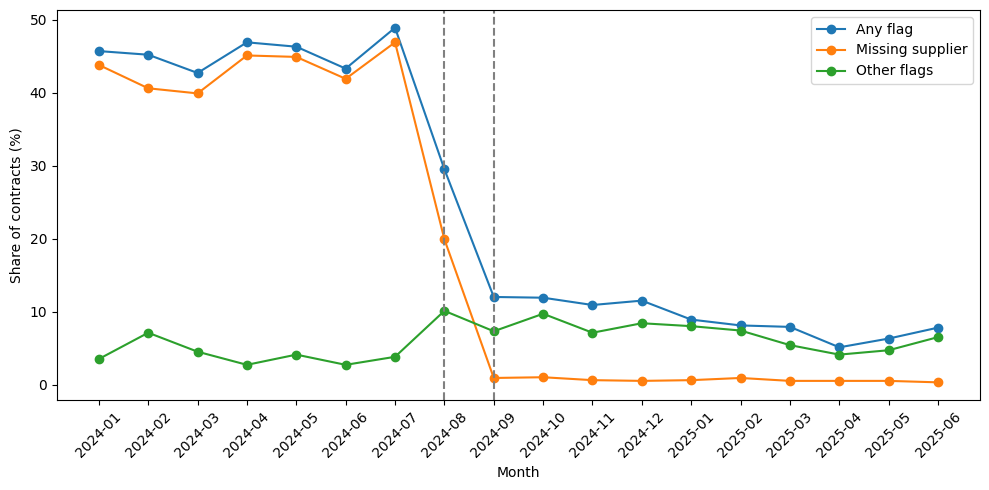

In [114]:
# STEP 27: Figure 1 for the paper
# Share of contracts flagged each month: any flag, missing supplier, and other flags

import matplotlib.pyplot as plt

# 1. Month labels for the bottom axis
month_labels = monthly.index.astype(str)

# 2. Draw the three lines
plt.figure(figsize=(10, 5))
plt.plot(month_labels, monthly["is_flagged"] * 100, label="Any flag", marker="o")
plt.plot(month_labels, monthly["no_supplier"] * 100, label="Missing supplier", marker="o")
plt.plot(month_labels, monthly_v2["flagged_other_v2"] * 100, label="Other flags", marker="o")

# 3. Mark the two reforms. August 2024 is the 8th month and September the 9th,
#    so on a zero-based axis they sit at 7 and 8.
plt.axvline(7, linestyle="--", color="gray")
plt.axvline(8, linestyle="--", color="gray")

# 4. Labels, then save
plt.xticks(rotation=45)
plt.xlabel("Month")
plt.ylabel("Share of contracts (%)")
plt.legend()
plt.tight_layout()
plt.savefig("figure1_flag_rates.png", dpi=200)
plt.show()